# Notebook 02 — Churn Overview & Trend

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business questions answered:**
- **Q1:** What is the current churn rate?
- **Q2:** Is churn increasing or decreasing?

**Evidence source:** `sql/03_historical_churn_Q1_Q2.sql` → `monthly_churn_metrics` table

**Findings register:** F001 (populated in Stage 3 pipeline)

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
from pathlib import Path

# Style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'sans-serif'

FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected to churn.db')

Connected to churn.db


## 1. Load Monthly Churn Metrics

In [2]:
df = pd.read_sql('SELECT * FROM monthly_churn_metrics ORDER BY month', conn)
df['month'] = pd.to_datetime(df['month'])
print(df.shape)
df.head()

       month  ...  total_churn_rate_pct
0 2024-02-01  ...                  8.08
1 2024-03-01  ...                  7.94
2 2024-04-01  ...                  6.88
3 2024-05-01  ...                  6.92
4 2024-06-01  ...                  6.87

[5 rows x 7 columns]

(23, 7)


## 2. Monthly Churn Rate Over Time (Q1 & Q2)

Saved to ..\outputs\figures/02_monthly_churn_trend.png


<cell>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


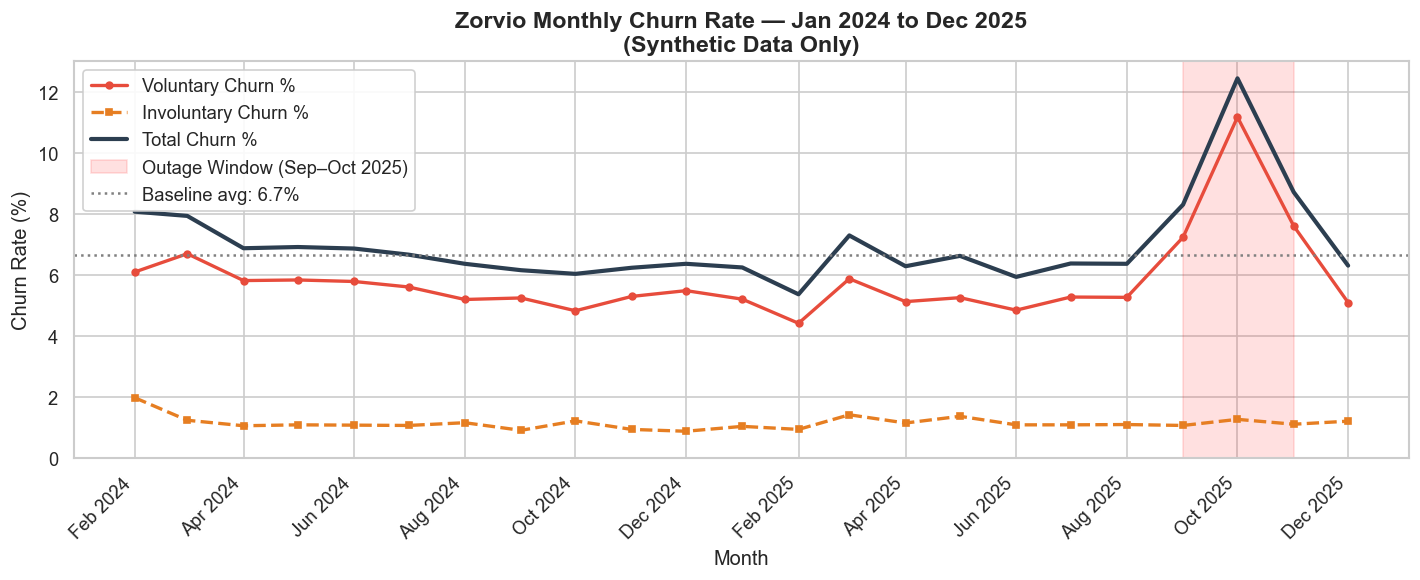

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df['month'], df['voluntary_churn_rate_pct'], label='Voluntary Churn %', color='#e74c3c', linewidth=2, marker='o', markersize=4)
ax.plot(df['month'], df['involuntary_churn_rate_pct'], label='Involuntary Churn %', color='#e67e22', linewidth=2, linestyle='--', marker='s', markersize=4)
ax.plot(df['month'], df['total_churn_rate_pct'], label='Total Churn %', color='#2c3e50', linewidth=2.5)

# Highlight outage period
ax.axvspan(pd.Timestamp('2025-09-01'), pd.Timestamp('2025-11-01'), alpha=0.12, color='red', label='Outage Window (Sep–Oct 2025)')

# Baseline reference line
baseline = df[~df['month'].isin(pd.to_datetime(['2025-09-01', '2025-10-01']))]['total_churn_rate_pct'].mean()
ax.axhline(baseline, color='gray', linestyle=':', linewidth=1.5, label=f'Baseline avg: {baseline:.1f}%')

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.xticks(rotation=45, ha='right')

ax.set_title('Zorvio Monthly Churn Rate — Jan 2024 to Dec 2025\n(Synthetic Data Only)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Churn Rate (%)')
ax.legend(loc='upper left', framealpha=0.9)
ax.set_ylim(0)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_monthly_churn_trend.png', bbox_inches='tight')
plt.show()
print(f'Saved to {FIGURES_DIR}/02_monthly_churn_trend.png')

## 3. Summary Statistics

In [4]:
# Exclude outage months for baseline
outage_months = pd.to_datetime(['2025-09-01', '2025-10-01'])
baseline_df = df[~df['month'].isin(outage_months)]
peak_row = df.loc[df['voluntary_churn_rate_pct'].idxmax()]

print('=== Q1: Current Churn Rate ===')
latest = df.sort_values('month').iloc[-1]
print(f"Latest month ({latest['month'].strftime('%b %Y')}):")
print(f"  Total churn rate:      {latest['total_churn_rate_pct']:.2f}%")
print(f"  Voluntary churn rate:  {latest['voluntary_churn_rate_pct']:.2f}%")
print(f"  Involuntary churn rate:{latest['involuntary_churn_rate_pct']:.2f}%")

print()
print('=== Q2: Trend ===')
print(f"Baseline avg total churn:     {baseline_df['total_churn_rate_pct'].mean():.2f}%")
print(f"Baseline avg voluntary churn: {baseline_df['voluntary_churn_rate_pct'].mean():.2f}%")
print(f"Peak voluntary churn: {peak_row['voluntary_churn_rate_pct']:.2f}% in {peak_row['month'].strftime('%b %Y')}")
print(f"Post-outage return to baseline: {df[df['month'] > pd.Timestamp('2025-10-01')]['total_churn_rate_pct'].mean():.2f}%")

print()
print('=== CAUTION: Causal language ===' )
print('The Sep/Oct 2025 spike is ASSOCIATED with the simulated outage event.')
print('This is not a causal claim. A real analysis would require a controlled experiment.')

=== Q1: Current Churn Rate ===
Latest month (Dec 2025):
  Total churn rate:      6.31%
  Voluntary churn rate:  5.10%
  Involuntary churn rate:1.21%

=== Q2: Trend ===
Baseline avg total churn:     6.67%
Baseline avg voluntary churn: 5.52%
Peak voluntary churn: 11.18% in Oct 2025
Post-outage return to baseline: 7.52%

=== CAUTION: Causal language ===
The Sep/Oct 2025 spike is ASSOCIATED with the simulated outage event.
This is not a causal claim. A real analysis would require a controlled experiment.


In [5]:
conn.close()